# Lab2 - Homework

Autor: Hubert Kozierkiewicz

## Pobieranie danych

Datasety:
- inter-station distances in 2022
- railway stations in 2023
- train disruptions between 2011 and 2023
- train services between 2019 and 2025

Dane pobrałem ręcznie, bo kod wywalał forbidden 403.

Pobrane tabele to:
tariff-distances-2022-01.csv
stations-2023-09.csv
disruption-20XX.csv
services-20XX.csv.gz


Wykonuje:

```bash
docker compose up -d
```

## Tabela Stations w DuckDB

In [80]:
import duckdb

db = duckdb.connect("homework.duckdb")

db.sql("""
CREATE TABLE IF NOT EXISTS stations AS
FROM 'data_homework/stations-2023-09.csv';
""")

db.sql("DESCRIBE stations;").show()

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ code        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ uic         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ name_short  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_medium │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_long   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ slug        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ type        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lat     │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lng     │ DOUB

## Tabele Services, Distances_long, Disruption i Stations

In [81]:
# Distances
db.sql("""
CREATE TABLE IF NOT EXISTS distances AS
FROM 'data_homework/tariff-distances-2022-01.csv';
""")

# Long Distances
db.sql("""
CREATE TABLE IF NOT EXISTS distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE station)
INTO NAME other_station VALUE distance;
""")

db.sql("SELECT * FROM distances_long LIMIT 5;").show()

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │ varchar  │
├─────────┼───────────────┼──────────┤
│ AC      │ AC            │ XXX      │
│ AC      │ AH            │ 82       │
│ AC      │ AHP           │ 83       │
│ AC      │ AHPR          │ 85       │
│ AC      │ AHZ           │ 90       │
└─────────┴───────────────┴──────────┘



In [82]:
# Disruptions
db.sql("INSTALL postgres; LOAD postgres;")

conn_string = "host=127.0.0.1 user=postgres password=postgres dbname=postgres"
db.sql(f"ATTACH IF NOT EXISTS '{conn_string}' AS pg (TYPE postgres);")

db.sql("""
CREATE TABLE IF NOT EXISTS pg.disruptions AS
FROM 'data_homework/disruptions-*.csv';
""")

db.sql("SELECT COUNT(*) AS total_disruptions FROM pg.disruptions;").show()

┌───────────────────┐
│ total_disruptions │
│       int64       │
├───────────────────┤
│             55864 │
└───────────────────┘



In [83]:
# Services
import os

parquet_path = "data_homework/services.parquet"

if not os.path.exists(parquet_path):
    db.sql(f"""
    COPY (SELECT * FROM 'data_homework/services-*.csv.gz')
    TO '{parquet_path}' (FORMAT PARQUET, COMPRESSION ZSTD);
    """)

db.sql(f"""
CREATE TABLE IF NOT EXISTS services AS
FROM '{parquet_path}';
""")

db.sql("SELECT COUNT(*) AS total_rows FROM services;").show()

┌────────────┐
│ total_rows │
│   int64    │
├────────────┤
│  155724169 │
└────────────┘



## Analizy i wizualizacje

Remember that each row represents single ride between stations, while the whole end-to-end train service has the same value in Service:RDT-ID column. Note that starting station for a service has NULL value in Stop:Arrival time column, while the end station has NULL value

### 1. Liczba pociągów ze stacji Amsterdam Central

In [84]:
db.sql("""
SELECT COUNT(*) AS departures
FROM services
WHERE "Stop:Station code" = 'ASD' AND "Stop:Departure time" IS NOT NULL;
""").show()

┌────────────┐
│ departures │
│   int64    │
├────────────┤
│    1985379 │
└────────────┘



### 2. Średnie opóźnienie x typ pociągu

In [85]:
db.sql("""
SELECT "Service:Type", AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
WHERE "Stop:Arrival delay" IS NOT NULL
GROUP BY "Service:Type"
ORDER BY avg_arrival_delay DESC;
""").show()

┌──────────────────────┬────────────────────┐
│     Service:Type     │ avg_arrival_delay  │
│       varchar        │       double       │
├──────────────────────┼────────────────────┤
│ Alpen Express        │  31.84254143646409 │
│ Krokus Express       │ 18.304347826086957 │
│ European Sleeper     │ 14.301185866408519 │
│ Nightjet             │    9.2749537091934 │
│ ICE                  │   7.76692176533566 │
│ Eurostar             │ 7.3792128485462545 │
│ ICE International    │  5.501485991808924 │
│ Thalys               │  5.390004541595087 │
│ Int. Trein           │  4.671220400728598 │
│ Nachttrein           │  3.765853658536585 │
│     ·                │                 ·  │
│     ·                │                 ·  │
│     ·                │                 ·  │
│ OV-bus ipv trein     │                0.0 │
│ Taxibus ipv trein    │                0.0 │
│ Metro i.p.v. trein   │                0.0 │
│ Metro                │                0.0 │
│ Tram ipv trein       │          

### 3. Zakłócenia x rok

In [86]:
db.sql("""
SELECT YEAR(start_time::TIMESTAMP) AS year, MODE(statistical_cause_en) AS most_common_cause
FROM pg.disruptions
GROUP BY year
ORDER BY year;
""").show()

┌───────┬───────────────────┐
│ year  │ most_common_cause │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2011 │ broken down train │
│  2012 │ points failure    │
│  2013 │ points failure    │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2016 │ broken down train │
│  2017 │ broken down train │
│  2018 │ broken down train │
│  2019 │ broken down train │
│  2020 │ broken down train │
│  2021 │ broken down train │
│  2022 │ broken down train │
│  2023 │ broken down train │
│  2024 │ broken down train │
├───────┴───────────────────┤
│ 14 rows         2 columns │
└───────────────────────────┘



### 4. Pociągi wyjeżdżające z Amsterdamu

In [87]:
db.sql("""
SELECT COUNT(*) AS departs_from_amsterdam
FROM services s
JOIN stations st ON s."Stop:Station code" = st.code
WHERE s."Stop:Arrival time" IS NULL AND st.name_long LIKE '%Amsterdam%';
""").show()

┌────────────────────────┐
│ departs_from_amsterdam │
│         int64          │
├────────────────────────┤
│                1308564 │
└────────────────────────┘



### 5. Połączenia transgraniczne

In [88]:
db.sql("""
SELECT COUNT(*) FILTER (WHERE st.country != 'NL') * 1.0 / COUNT(*) AS fraction_outside_nl
FROM services s
JOIN stations st ON s."Stop:Station code" = st.code
WHERE s."Stop:Departure time" IS NULL;
""").show()

┌──────────────────────┐
│ fraction_outside_nl  │
│        double        │
├──────────────────────┤
│ 0.038316558943375434 │
└──────────────────────┘



### 6. Największy dystans między stacjami w holandii

In [89]:
db.sql("""
SELECT s1.name_long AS station1, s2.name_long AS station2, d.distance
FROM distances_long d
JOIN stations s1 ON d.station = s1.code
JOIN stations s2 ON d.other_station = s2.code
WHERE s1.country = 'NL' AND s2.country = 'NL'
ORDER BY d.distance DESC
LIMIT 1;
""").show()

┌────────────────┬────────────────┬──────────┐
│    station1    │    station2    │ distance │
│    varchar     │    varchar     │ varchar  │
├────────────────┼────────────────┼──────────┤
│ Santpoort Zuid │ Santpoort Zuid │ XXX      │
└────────────────┴────────────────┴──────────┘



### 7. Średnie opóżnienie x przewoźnik + wizualizacja

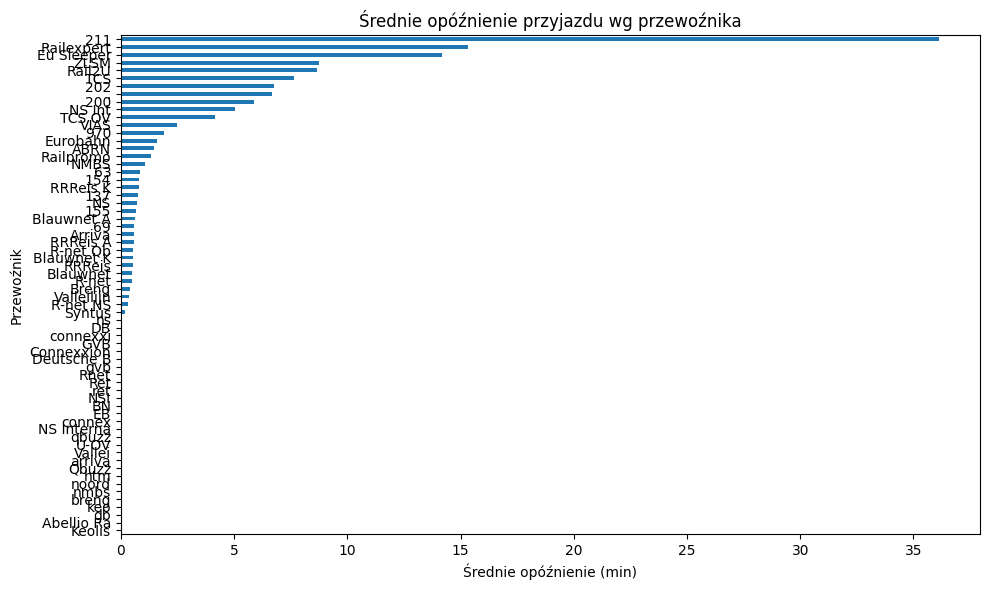

In [90]:
import matplotlib.pyplot as plt

df_company = db.sql("""
SELECT "Service:Company", AVG("Stop:Arrival delay") AS avg_delay
FROM services
WHERE "Stop:Arrival delay" IS NOT NULL
GROUP BY "Service:Company"
ORDER BY avg_delay ASC;
""").df()

ax = df_company.plot.barh(x="Service:Company", y="avg_delay", figsize=(10, 6), legend=False)
ax.set_title("Średnie opóźnienie przyjazdu wg przewoźnika")
ax.set_xlabel("Średnie opóźnienie (min)")
ax.set_ylabel("Przewoźnik")
plt.tight_layout()
plt.show()

### 8. Liczba zakłóceń x rok + wiz

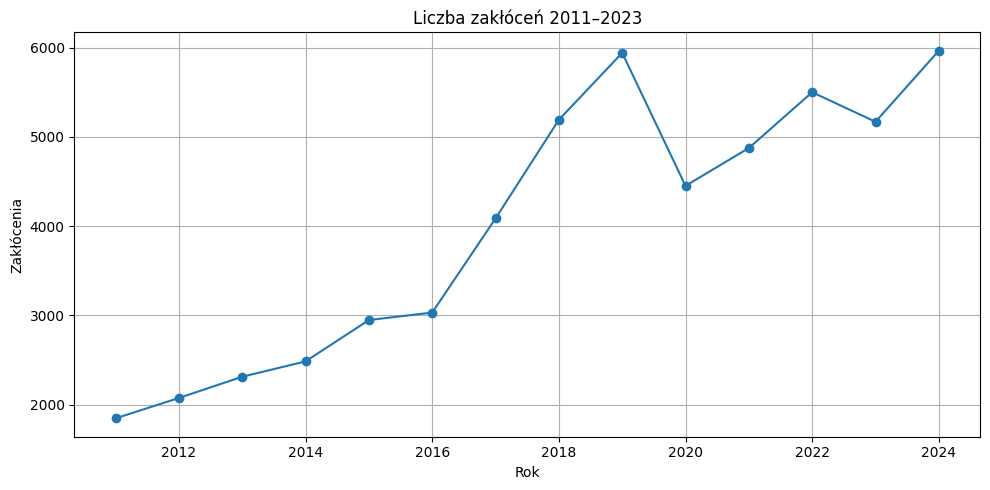

In [91]:
df_disruptions = db.sql("""
SELECT YEAR(start_time::TIMESTAMP) AS year, COUNT(*) AS num_disruptions
FROM pg.disruptions
GROUP BY year
ORDER BY year;
""").df()

ax = df_disruptions.plot.line(x="year", y="num_disruptions", marker="o", figsize=(10, 5), legend=False)
ax.set_title("Liczba zakłóceń 2011–2023")
ax.set_xlabel("Rok")
ax.set_ylabel("Zakłócenia")
plt.grid(True)
plt.tight_layout()
plt.show()

### 9. Procent odwołanych pociągów

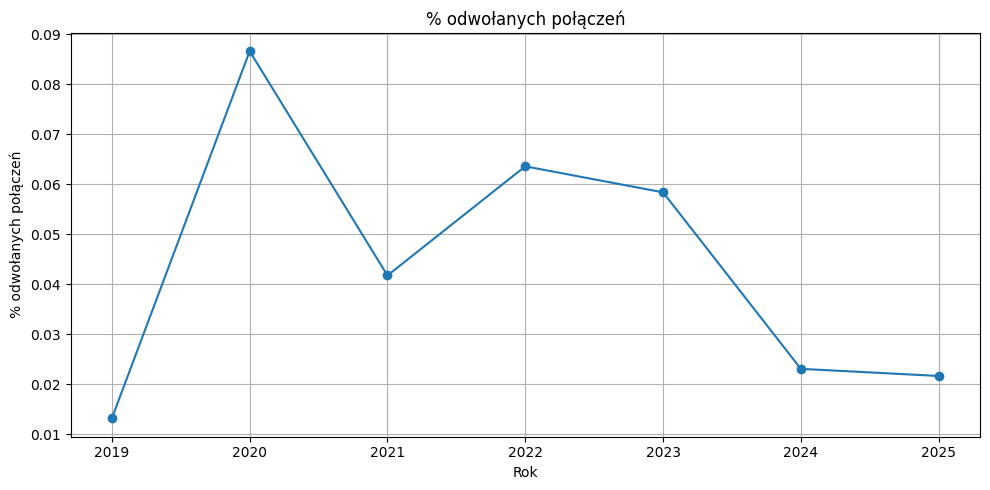

In [92]:
df_cancelled = db.sql("""
SELECT YEAR("Service:Date") AS year, AVG(("Service:Completely cancelled"::INT)) AS cancelled_fraction
FROM (
    SELECT DISTINCT "Service:RDT-ID", "Service:Date", "Service:Completely cancelled"
    FROM services
)
GROUP BY year
ORDER BY year;
""").df()

ax = df_cancelled.plot.line(x="year", y="cancelled_fraction", marker="o", figsize=(10, 5), legend=False)
ax.set_title("% odwołanych połączeń")
ax.set_xlabel("Rok")
ax.set_ylabel("% odwołanych połączeń")
plt.grid(True)
plt.tight_layout()
plt.show()

# Długoś połączeń + okno

### Tabela station_connections

In [93]:
db.sql("DROP TABLE station_connections;")

In [94]:
db.sql("""
CREATE TABLE IF NOT EXISTS station_connections AS
WITH segments AS (
    SELECT "Service:RDT-ID", "Stop:Station code" AS start_station_code,
        LEAD("Stop:Station code") OVER (
            PARTITION BY "Service:RDT-ID"
            ORDER BY "Stop:Departure time"
        ) AS end_station_code
    FROM services
)
SELECT DISTINCT ON (s.start_station_code, s.end_station_code) s."Service:RDT-ID", s.start_station_code, s.end_station_code, dist.distance
FROM segments s
JOIN distances_long dist ON s.start_station_code = dist.station AND s.end_station_code = dist.other_station
WHERE s.end_station_code IS NOT NULL AND dist.distance != 'XXX' AND s.start_station_code != s.end_station_code;
""")

db.sql("SELECT * FROM station_connections LIMIT 5;").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │ varchar  │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│        4660197 │ ZWD                │ BRD              │ 7        │
│        4663149 │ ALM                │ LLS              │ 24       │
│        4665484 │ BSMZ               │ HVSM             │ 4        │
│        4666249 │ UTLN               │ UTVR             │ 3        │
│        4666249 │ LLZM               │ ZTMO             │ 2        │
└────────────────┴────────────────────┴──────────────────┴──────────┘



## Max odległość + histogram

In [95]:
db.sql("""
SELECT *
FROM station_connections
ORDER BY distance DESC
LIMIT 1;
""").show()

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │ varchar  │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│        2966245 │ O                  │ GD               │ 99       │
└────────────────┴────────────────────┴──────────────────┴──────────┘



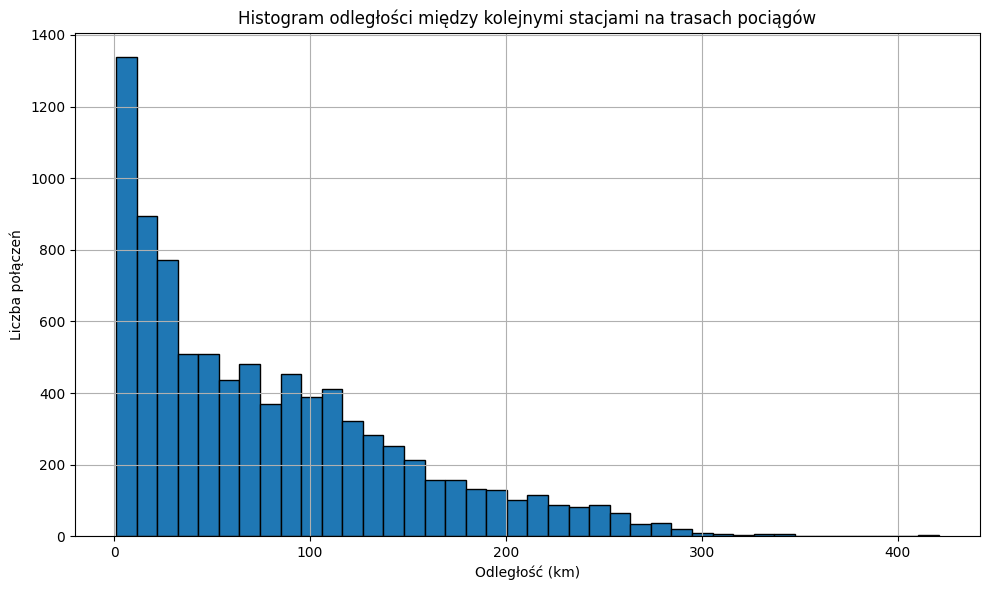

In [ ]:
df_distances = db.sql("SELECT distance FROM station_connections WHERE distance IS NOT NULL;").df()
# Musiałem tutaj przeprowadzić konwersję, bo nie chciałem już komplikować sql wyżej
df_distances["distance"] = pd.to_numeric(df_distances["distance"], errors="coerce")

ax = df_distances["distance"].plot.hist(bins=40, figsize=(10, 6), edgecolor="black")
ax.set_title("Histogram odległości między kolejnymi stacjami na trasach pociągów")
ax.set_xlabel("Odległość (km)")
ax.set_ylabel("Liczba połączeń")
plt.grid(True)
plt.tight_layout()
plt.show()